# Text-to-Video Generation with Cosmos3-Edge and OpenVINO

[Cosmos3-Edge](https://huggingface.co/nvidia/Cosmos3-Edge) is the smallest model of NVIDIA's [Cosmos 3](https://research.nvidia.com/labs/cosmos-lab/cosmos3/) family of omnimodal world models for Physical AI ([technical report](https://research.nvidia.com/labs/cosmos-lab/cosmos3/technical-report.pdf)). It is a Mixture-of-Transformers: an autoregressive text tower reads the prompt, and a diffusion tower that attends to it denoises video latents, which a Wan VAE decodes into frames.

This tutorial generates 17-frame, 256×256 videos from a text prompt and:

* downloads the public checkpoint from Hugging Face,
* rebuilds the text tower and one denoising step as static-shape PyTorch modules and runs them as a reference,
* converts the text tower, the denoising step and the VAE decoder to OpenVINO IR, optimizes them and verifies the conversion,
* generates videos with a selectable number of denoising steps on the selected device, such as CPU or GPU.

#### Table of contents:

- [Prerequisites](#Prerequisites)
- [Download the model](#Download-the-model)
- [Load the PyTorch model](#Load-the-PyTorch-model)
    - [Run the PyTorch model](#Run-the-PyTorch-model)
- [Convert the models to OpenVINO IR](#Convert-the-models-to-OpenVINO-IR)
- [Run OpenVINO inference](#Run-OpenVINO-inference)
    - [Select inference device](#Select-inference-device)
    - [Generate a video](#Generate-a-video)
    - [Verify the conversion](#Verify-the-conversion)
- [Clean up](#Clean-up)

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/cosmos3-edge-text-to-video/cosmos3-edge-text-to-video.ipynb" />

## Prerequisites
[back to top ⬆️](#Table-of-contents:)

In [1]:
%pip install -q "openvino>=2026.4.1" "torch>=2.14" --extra-index-url https://download.pytorch.org/whl/cpu
%pip install -q "diffusers>=0.41.0" "transformers>=5.20" accelerate huggingface_hub "matplotlib>=3.4" ipywidgets imageio imageio-ffmpeg tqdm requests

from pathlib import Path
import requests

if not Path("notebook_utils.py").exists():
    r = requests.get("https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/notebook_utils.py")
    with open("notebook_utils.py", "w") as f:
        f.write(r.text)

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("cosmos3-edge-text-to-video.ipynb")

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


The PyTorch wrappers that make the generation path traceable with static shapes, the prompt pre-processing and the video utilities live in `cosmos3_edge_helper.py` next to this notebook.

In [2]:
import copy
import gc
import re
import time

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import openvino as ov
import torch
from IPython.display import Video

import cosmos3_edge_helper as cosmos

MODEL_ID = "nvidia/Cosmos3-Edge"
MODEL_DIR = Path("model")
CHECKPOINT_DIR = MODEL_DIR / "Cosmos3-Edge"
OUTPUT_DIR = Path("output")
TEXT_ENCODER_IR_PATH = MODEL_DIR / "cosmos3_edge_text_encoder.xml"
DENOISER_IR_PATH = MODEL_DIR / "cosmos3_edge_denoiser.xml"
VAE_DECODER_IR_PATH = MODEL_DIR / "cosmos3_edge_vae_decoder_f16_opt.xml"
VAE_DECODER_INT8_IR_PATH = MODEL_DIR / "cosmos3_edge_vae_decoder_int8.xml"
USE_INT8_DECODER = True

STEPS = 8
GUIDANCE_SCALE = 6.0
MAX_TEXT_LENGTH = 256
SEED = 1
PROMPT = "A colorful spinning top rotates quickly on a wooden table. Close-up, fixed camera, bright lighting."

torch.set_grad_enabled(False)
core = ov.Core()

## Download the model
[back to top ⬆️](#Table-of-contents:)

The checkpoint is public on [Hugging Face](https://huggingface.co/nvidia/Cosmos3-Edge) under the [OpenMDW 1.1](https://openmdw.ai/license/1-1/) license. Text-to-video needs only the text tokenizer, the transformer, the VAE and the scheduler configuration, about 8.2 GB; the vision encoder and example assets are skipped.

In [3]:
from huggingface_hub import snapshot_download

snapshot_download(
    MODEL_ID,
    local_dir=CHECKPOINT_DIR,
    allow_patterns=["model_index.json", "scheduler/*", "text_tokenizer/*", "transformer/*", "vae/*"],
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

'/home/alex/cosmos3_edge_bench/Cosmos3-Edge'

## Load the PyTorch model
[back to top ⬆️](#Table-of-contents:)

The checkpoint is loaded with `Cosmos3OmniPipeline` from Diffusers. For text-to-video, generation reduces to three parts:

* **Text tower.** A causal transformer reads the prompt and an unconditional prompt and produces, in every layer, the keys and values that the video tokens attend to. It runs once per prompt.
* **Diffusion tower.** It denoises the 48×5×16×16 video latent with classifier-free guidance; the conditional and unconditional rows run together as one batch. The UniPC scheduler calls it once per denoising step, so more steps give the model more refinement passes at a proportionally higher cost.
* **Wan VAE decoder.** It turns the latent into 17 frames of 256×256 pixels.

`TextKV` and `DenoiseStep` in `cosmos3_edge_helper.py` wrap the text tower and one denoising step with static input shapes, and `run_denoising` drives the steps with the UniPC scheduler.

In [4]:
from diffusers import Cosmos3OmniPipeline
from diffusers.schedulers.scheduling_unipc_multistep import UniPCMultistepScheduler

pipe = Cosmos3OmniPipeline.from_pretrained(CHECKPOINT_DIR, torch_dtype=torch.float32, enable_safety_checker=False)
transformer, vae = pipe.transformer.eval(), pipe.vae.eval()
scheduler_config = UniPCMultistepScheduler.from_config(pipe.scheduler.config, flow_shift=10.0, use_karras_sigmas=False).config
latent_mean = np.asarray(vae.config.latents_mean, dtype=np.float32).reshape(1, -1, 1, 1, 1)
latent_std = np.asarray(vae.config.latents_std, dtype=np.float32).reshape(1, -1, 1, 1, 1)
del pipe
gc.collect()

text_encoder = cosmos.TextKV(transformer=transformer).eval()
denoiser = cosmos.DenoiseStep(transformer=transformer, guidance_scale=GUIDANCE_SCALE).eval()
vae_decoder = cosmos.VAEDecoder(vae=vae).eval()

for name, model in (("Transformer", transformer), ("VAE", vae)):
    print(f"{name}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters")

/home/alex/cosmos3_edge_bench/.venv/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/4 [00:00<?, ?it/s]

The config attributes {'clip_output': False} were passed to AutoencoderKLWan, but are not expected and will be ignored. Please verify your config.json configuration file.


The config attributes {'backbone_type': 'cosmos3_edge_nemotron_dense', 'temporal_compression_factor': 4} were passed to Cosmos3OmniTransformer, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Transformer: 3370 M parameters
VAE: 705 M parameters


### Run the PyTorch model
[back to top ⬆️](#Table-of-contents:)

`PromptPreprocessor` tokenizes the prompt together with an unconditional prompt for classifier-free guidance and builds the 3D rotary position tables, all padded to fixed shapes. The model runs on CPU in FP32 and gives us a reference to validate the converted models against.

In [5]:
preprocessor = cosmos.PromptPreprocessor(checkpoint=CHECKPOINT_DIR, lmax=MAX_TEXT_LENGTH)
prompt_inputs = preprocessor(prompt=PROMPT)
initial_latent = torch.randn(cosmos.LATENT_SHAPE, generator=torch.Generator().manual_seed(SEED))

text_input = tuple(torch.from_numpy(prompt_inputs[name]) for name in cosmos.TEXT_INPUT_NAMES)
text_k, text_v = text_encoder(*text_input)
prompt_tensors = tuple(torch.from_numpy(prompt_inputs[name]) for name in ("text_mask", "gen_cos", "gen_sin"))
denoiser_input = (initial_latent, torch.tensor([999.0]), text_k, text_v, *prompt_tensors)


def pt_step(x: np.ndarray, timestep: np.ndarray) -> np.ndarray:
    return denoiser(torch.from_numpy(x), torch.from_numpy(timestep), text_k, text_v, *prompt_tensors).numpy()


pt_latent = cosmos.run_denoising(step_fn=pt_step, latent=initial_latent.numpy(), scheduler_config=scheduler_config, steps=STEPS)
pt_decoder_input = torch.from_numpy(pt_latent * latent_std + latent_mean)
pt_video = vae_decoder(pt_decoder_input).numpy()

print(f"Prompt tokens (conditional, unconditional): {prompt_inputs['token_lengths']}")
print(f"Denoising timesteps: {[round(float(t), 1) for t in cosmos.make_scheduler(config=scheduler_config, steps=STEPS).timesteps]}")
print(f"Final latent {pt_latent.shape} -> video {pt_video.shape}")

Prompt tokens (conditional, unconditional): [71, 54]
Denoising timesteps: [999.0, 985.0, 967.0, 943.0, 908.0, 856.0, 768.0, 587.0]
Final latent (1, 48, 5, 16, 16) -> video (1, 3, 17, 256, 256)


## Convert the models to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR). `ov.convert_model` traces the model with an example input and returns an `ov.Model`, which `ov.save_model` writes to disk with FP16-compressed weights. Conversion takes several minutes, and the notebook needs up to about 20 GB of host memory while the PyTorch and OpenVINO models are both loaded.

In [6]:
MODEL_DIR.mkdir(exist_ok=True)

conversions = (
    (TEXT_ENCODER_IR_PATH, text_encoder, text_input, cosmos.TEXT_INPUT_NAMES, ("text_k", "text_v")),
    (DENOISER_IR_PATH, denoiser, denoiser_input, cosmos.DENOISER_INPUT_NAMES, ("velocity",)),
)
for ir_path, module, example_input, input_names, output_names in conversions:
    if ir_path.exists():
        continue
    ov_model = ov.convert_model(module, example_input=example_input)
    for port, name in zip(ov_model.inputs, input_names):
        port.get_tensor().set_names({name})
    for port, name in zip(ov_model.outputs, output_names):
        port.get_tensor().set_names({name})
    ov_model.reshape({port: list(tensor.shape) for port, tensor in zip(ov_model.inputs, example_input)})
    print(f"{ir_path.name}: folded {cosmos.sdpa_to_rank4(model=ov_model)} grouped-query attentions into 4D attention")
    ov_model.validate_nodes_and_infer_types()
    ov.save_model(model=ov_model, output_model=ir_path)
    del ov_model
    gc.collect()

In [7]:
if not VAE_DECODER_IR_PATH.exists():
    swapped = cosmos.use_nearest_upsampling(model=vae_decoder)
    max_diff = float(np.abs(vae_decoder(pt_decoder_input).numpy() - pt_video).max())
    if max_diff:
        raise RuntimeError(f"'nearest' upsampling changed the decoder output by up to {max_diff}")
    print(f"Switched {swapped} upsampling layers to 'nearest' with bit-identical output")

    # A half-precision export keeps WanRMSNorm's reduction in f32, which the graph rewrites match on.
    decoder_f16 = cosmos.VAEDecoder(vae=copy.deepcopy(vae).half()).eval()
    ov_model = ov.convert_model(decoder_f16, example_input=(pt_decoder_input.half(),))
    ov_model.inputs[0].get_tensor().set_names({"z"})
    ov_model.outputs[0].get_tensor().set_names({"sample"})
    ov_model.reshape({ov_model.inputs[0]: list(pt_decoder_input.shape)})
    raw_path = MODEL_DIR / "cosmos3_edge_vae_decoder_f16_raw.xml"
    ov.save_model(model=ov_model, output_model=raw_path)
    del ov_model, decoder_f16
    gc.collect()

    ov_model = core.read_model(raw_path)
    print("Decoder graph rewrites:", cosmos.optimize_vae_decoder(model=ov_model))
    ov.save_model(model=ov_model, output_model=VAE_DECODER_IR_PATH, compress_to_fp16=False)
    del ov_model
    gc.collect()
    raw_path.unlink()
    raw_path.with_suffix(".bin").unlink()

if not VAE_DECODER_INT8_IR_PATH.exists():
    calibration_device = "GPU" if "GPU" in core.available_devices else "CPU"
    ov_model, quantized = cosmos.quantize_vae_decoder(model_path=VAE_DECODER_IR_PATH, latent=pt_decoder_input.numpy(), device=calibration_device)
    print(f"Mixed INT8 decoder: {quantized} convolutions quantized, the sensitive ones kept in FP16")
    ov.save_model(model=ov_model, output_model=VAE_DECODER_INT8_IR_PATH, compress_to_fp16=False)
    del ov_model
    gc.collect()

# The PyTorch models are no longer needed; free their memory before compiling the OpenVINO models.
del text_encoder, denoiser, vae_decoder, transformer, vae, text_k, text_v, denoiser_input
gc.collect()

for path in (TEXT_ENCODER_IR_PATH, DENOISER_IR_PATH, VAE_DECODER_IR_PATH, VAE_DECODER_INT8_IR_PATH):
    model = core.read_model(path)
    print(
        f"{path.name}: {len(model.inputs)} inputs, {len(model.get_ordered_ops())} operations, weights {path.with_suffix('.bin').stat().st_size / 2**30:.1f} GB"
    )
del model

cosmos3_edge_text_encoder.xml: 3 inputs, 4377 operations, weights 3.0 GB
cosmos3_edge_denoiser.xml: 7 inputs, 7332 operations, weights 2.6 GB
cosmos3_edge_vae_decoder_f16_opt.xml: 1 inputs, 3915 operations, weights 1.0 GB
cosmos3_edge_vae_decoder_int8.xml: 1 inputs, 4635 operations, weights 1.0 GB


## Run OpenVINO inference
[back to top ⬆️](#Table-of-contents:)

### Select inference device
[back to top ⬆️](#Table-of-contents:)

Select a device from the dropdown list for running inference using OpenVINO, the prompt, the seed of the initial noise and the number of denoising steps. Different seeds give different videos for the same prompt. More steps refine the video further, and generation time grows with every step: 4 steps give a quick preview, 8 steps a clean video, and 16 or 30 steps the most detail.

In [8]:
from notebook_utils import device_widget

device = device_widget(default="GPU" if "GPU" in core.available_devices else "CPU", exclude=["NPU", "AUTO"])
prompt = widgets.Text(value=PROMPT, description="Prompt:", layout=widgets.Layout(width="90%"))
seed = widgets.IntText(value=SEED, description="Seed:")
steps = widgets.Dropdown(options=[4, 8, 16, 30], value=STEPS, description="Steps:")

widgets.VBox([device, prompt, seed, steps])

### Generate a video
[back to top ⬆️](#Table-of-contents:)

`Cosmos3EdgePipeline` runs the text encoder once, the denoising step once per scheduler step and then the VAE decoder, and records how long each stage takes. The video is saved as a 20 FPS MP4 in the `output` directory. Re-run this cell after changing the device, the prompt, the seed or the number of steps.

17 frames on GPU | prompt pre-processing: 123 ms | text encoder: 301 ms | 8 denoising steps: 1085 ms | VAE decoder: 702 ms


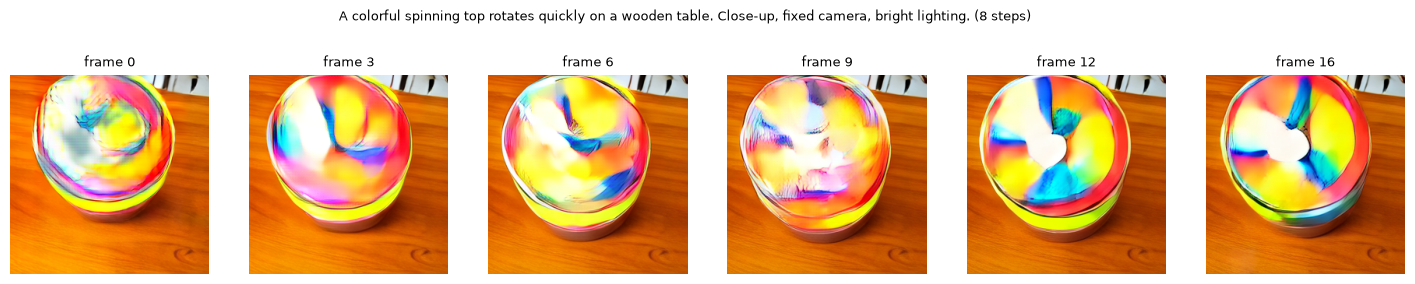

In [9]:
class Cosmos3EdgePipeline:
    def __init__(
        self,
        core: ov.Core,
        device_name: str,
        text_encoder_path: Path,
        denoiser_path: Path,
        decoder_path: Path,
        preprocessor: cosmos.PromptPreprocessor,
        scheduler_config: dict,
        latent_mean: np.ndarray,
        latent_std: np.ndarray,
    ):
        """
        Compile the text encoder, the denoising step and the VAE decoder and keep what is needed to turn a prompt into a video.

        :param core: OpenVINO runtime core
        :param device_name: inference device, for example "CPU" or "GPU"
        :param text_encoder_path: path to the text encoder IR
        :param denoiser_path: path to the denoising step IR
        :param decoder_path: path to the VAE decoder IR
        :param preprocessor: builds the static prompt tensors
        :param scheduler_config: UniPC scheduler configuration
        :param latent_mean: per-channel mean used to unnormalize the generated latent
        :param latent_std: per-channel standard deviation used to unnormalize the generated latent
        """
        config = {"PERFORMANCE_HINT": "LATENCY"}
        self.text_request = core.compile_model(model=text_encoder_path, device_name=device_name, config=config).create_infer_request()
        self.step_request = core.compile_model(model=denoiser_path, device_name=device_name, config=config).create_infer_request()
        self.decoder = core.compile_model(model=decoder_path, device_name=device_name, config=config)
        self.preprocessor = preprocessor
        self.scheduler_config = scheduler_config
        self.latent_mean = latent_mean
        self.latent_std = latent_std
        self.latent = None
        self.timings = {}

    def decode(self, latent: np.ndarray) -> np.ndarray:
        """
        Decode a normalized latent into a video.

        :param latent: video latent [1, 48, 5, 16, 16] as produced by the generator
        :returns: video [1, 3, frames, height, width] in [-1, 1]
        """
        decoder_input = (latent * self.latent_std + self.latent_mean).astype(np.float16)
        return self.decoder(decoder_input)[0].astype(np.float32)

    def denoise_step(self, latent: np.ndarray, timestep: np.ndarray) -> np.ndarray:
        """
        Run one denoising step.

        :param latent: current latent [1, 48, 5, 16, 16]
        :param timestep: scheduler timestep, shape [1]
        :returns: guided velocity with the shape of the latent
        """
        return self.step_request.infer({"vision_latents": latent, "timestep": timestep})[0].copy()

    def __call__(self, prompt: str, seed: int, steps: int, negative_prompt: str = None) -> np.ndarray:
        """
        Generate a video from a text prompt.

        :param prompt: text description of the video
        :param seed: seed of the initial noise
        :param steps: number of denoising steps
        :param negative_prompt: optional description of what to avoid
        :returns: video [1, 3, frames, height, width] in [-1, 1]
        """
        t0 = time.perf_counter()
        inputs = self.preprocessor(prompt=prompt, negative_prompt=negative_prompt)
        noise = torch.randn(cosmos.LATENT_SHAPE, generator=torch.Generator().manual_seed(seed)).numpy()
        t1 = time.perf_counter()
        self.text_request.infer({name: inputs[name] for name in cosmos.TEXT_INPUT_NAMES})
        for name in ("text_k", "text_v"):
            self.step_request.set_tensor(name, self.text_request.get_tensor(name))
        for name in ("text_mask", "gen_cos", "gen_sin"):
            self.step_request.set_tensor(name, ov.Tensor(inputs[name]))
        t2 = time.perf_counter()
        self.latent = cosmos.run_denoising(step_fn=self.denoise_step, latent=noise, scheduler_config=self.scheduler_config, steps=steps)
        t3 = time.perf_counter()
        video = self.decode(latent=self.latent)
        self.timings = {
            "prompt pre-processing": t1 - t0,
            "text encoder": t2 - t1,
            f"{steps} denoising steps": t3 - t2,
            "VAE decoder": time.perf_counter() - t3,
        }
        return video


pipeline = None  # release previously compiled models before compiling again
gc.collect()
pipeline = Cosmos3EdgePipeline(
    core=core,
    device_name=device.value,
    text_encoder_path=TEXT_ENCODER_IR_PATH,
    denoiser_path=DENOISER_IR_PATH,
    decoder_path=VAE_DECODER_INT8_IR_PATH if USE_INT8_DECODER else VAE_DECODER_IR_PATH,
    preprocessor=preprocessor,
    scheduler_config=scheduler_config,
    latent_mean=latent_mean,
    latent_std=latent_std,
)
video = pipeline(prompt=prompt.value, seed=seed.value, steps=steps.value)
print(f"{video.shape[2]} frames on {device.value} | " + " | ".join(f"{stage}: {seconds * 1000:.0f} ms" for stage, seconds in pipeline.timings.items()))

frames = cosmos.to_frames(video=video)
shown = np.linspace(0, len(frames) - 1, 6, dtype=int)
fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.4))
for ax, index in zip(axes, shown):
    ax.imshow(frames[index])
    ax.set_title(f"frame {index}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{prompt.value} ({steps.value} steps)", fontsize=9)
plt.show()

OUTPUT_DIR.mkdir(exist_ok=True)
prompt_slug = re.sub(r"[^a-z0-9]+", "_", prompt.value.lower()).strip("_")[:64]
video_path = cosmos.save_video(video=video, path=OUTPUT_DIR / f"cosmos3_edge_{prompt_slug}_{steps.value}steps.mp4")
Video(video_path, embed=True, width=384)

### Verify the conversion
[back to top ⬆️](#Table-of-contents:)

The OpenVINO pipeline receives the same prompt and initial noise as the PyTorch run above, and the outputs are compared stage by stage:

* **Generator:** cosine similarity of the final latent; values close to 1.0 mean the conversion is numerically faithful.
* **VAE decoder:** the OpenVINO decoder decodes the PyTorch latent, so its PSNR against the PyTorch video isolates the decoder's own error, including INT8 quantization.
* **End to end:** PSNR of the whole OpenVINO video against the PyTorch video. Small latent differences are amplified by the decoder, so this value is lower than the two above.

PSNR is computed on the 8-bit frames; higher is better.

In [10]:
def cosine(a: np.ndarray, b: np.ndarray) -> float:
    a, b = a.ravel().astype(np.float64), b.ravel().astype(np.float64)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


def psnr(reference: np.ndarray, video: np.ndarray) -> float:
    mse = np.mean((cosmos.to_frames(video=video).astype(np.float64) - cosmos.to_frames(video=reference)) ** 2)
    return float(10 * np.log10(255**2 / mse))


ov_video = pipeline(prompt=PROMPT, seed=SEED, steps=STEPS)
ov_decoded_pt_latent = pipeline.decode(latent=pt_latent)

print(f"Generator    final latent cosine : {cosine(a=pt_latent, b=pipeline.latent):.6f}")
print(f"VAE decoder  video PSNR          : {psnr(reference=pt_video, video=ov_decoded_pt_latent):.1f} dB")
print(f"End to end   video PSNR          : {psnr(reference=pt_video, video=ov_video):.1f} dB")

Generator    final latent cosine : 0.999390
VAE decoder  video PSNR          : 38.6 dB
End to end   video PSNR          : 32.7 dB


## Clean up
[back to top ⬆️](#Table-of-contents:)

The checkpoint and the converted models take about 16 GB in the `model` directory. Uncomment and run the cell below to delete them and the generated videos.

In [11]:
# import shutil

# shutil.rmtree(MODEL_DIR, ignore_errors=True)
# shutil.rmtree(OUTPUT_DIR, ignore_errors=True)